In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python analysis environment is working.")

Matplotlib is building the font cache; this may take a moment.


Python analysis environment is working.


In [2]:
import pandas as pd

file = "THz_PCF_Baseline_Postprocessed.xlsx"

df = pd.read_excel(file, sheet_name="Master_Data")

print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head(10))

Rows and columns: (130, 14)

Column names:
['Cell type', 'Status', 'RI', 'Frequency (THz)', 'Re(neff)', 'Im(neff)', 'Pcore (W)', 'Ptotal (W)', 'Aeff (m^2)', 'Pfrac', 'TPF (%)', 'RS (%)', 'CL (dB/m)', 'NA']


,Cell type,Status,RI,Frequency (THz),Re(neff),Im(neff),Pcore (W),Ptotal (W),Aeff (m^2),Pfrac,TPF (%),RS (%),CL (dB/m),NA
0,Blood,Healthy,1.376,0.8,1.2699,-6.618900e-08,5.852600e-08,7.547900e-08,1.260600e-07,0.775394,77.539448,84.017860,9.639506e-03,0.511637
1,Blood,Healthy,1.376,1.0,1.3045,-4.225800e-10,8.234300e-08,9.954200e-08,1.074900e-07,0.827219,82.721866,87.255874,7.692862e-05,0.458479
2,Blood,Healthy,1.376,1.2,1.3257,-4.711800e-12,1.094400e-07,1.284100e-07,9.973900e-08,0.852270,85.227007,88.460709,1.029312e-06,0.407557
3,Blood,Healthy,1.376,1.4,1.3396,-9.865400e-14,1.381800e-07,1.599600e-07,9.663000e-08,0.863841,86.384096,88.731350,2.514327e-08,0.362255
4,Blood,Healthy,1.376,1.6,1.3493,-3.804500e-15,1.665600e-07,1.920900e-07,9.616500e-08,0.867094,86.709355,88.425163,1.108145e-09,0.322660
5,Blood,Healthy,1.376,1.8,1.3564,-2.518900e-16,1.921700e-07,2.224600e-07,9.758500e-08,0.863841,86.384069,87.632320,8.253961e-11,0.288053
6,Blood,Healthy,1.376,2.0,1.3619,1.069700e-16,2.123600e-07,2.485000e-07,1.005600e-07,0.854567,85.456740,86.341490,3.894673e-11,0.257682
7,Blood,Healthy,1.376,2.2,1.3664,1.619000e-15,2.245900e-07,2.677800e-07,1.048200e-07,0.838711,83.871088,84.460346,6.484082e-10,0.231041
8,Blood,Healthy,1.376,2.4,1.3703,2.032900e-16,2.270500e-07,2.786100e-07,1.097200e-07,0.814938,81.493844,81.832832,8.881908e-11,0.208103
9,Blood,Healthy,1.376,2.6,1.3739,5.669400e-16,2.194600e-07,2.808300e-07,1.136400e-07,0.781469,78.146922,78.266369,2.683425e-10,0.189482


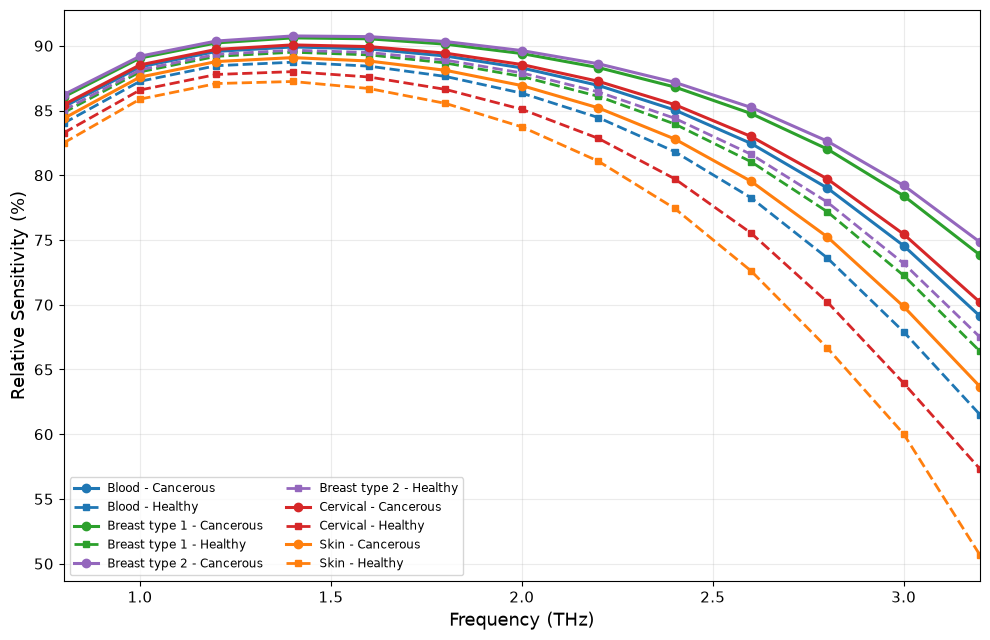

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("Figures").mkdir(exist_ok=True)

cell_types = [
    "Blood",
    "Breast type 1",
    "Breast type 2",
    "Cervical",
    "Skin"
]

colors = {
    "Blood": "tab:blue",
    "Breast type 1": "tab:green",
    "Breast type 2": "tab:purple",
    "Cervical": "tab:red",
    "Skin": "tab:orange"
}

plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["RS (%)"],
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy["RS (%)"],
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Relative Sensitivity (%)", fontsize=13)

plt.xlim(0.8, 3.2)
plt.tick_params(axis="both", labelsize=11)

plt.grid(True, alpha=0.25)
plt.legend(fontsize=8.5, ncol=2, frameon=True)

plt.tight_layout()

plt.savefig(
    "Figures/Relative_Sensitivity_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Relative_Sensitivity_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

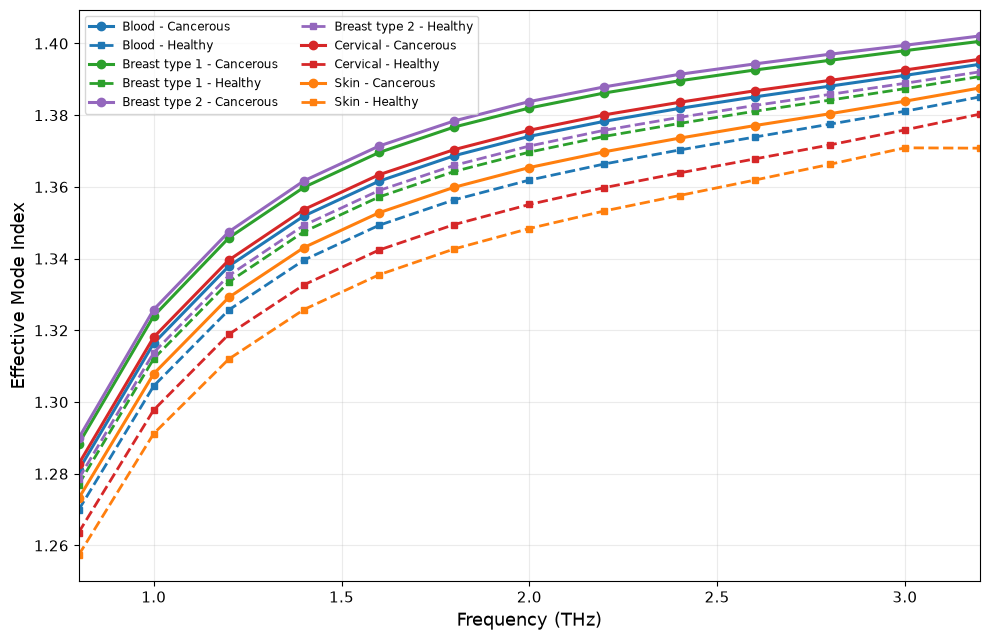

In [5]:
plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["Re(neff)"],
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy["Re(neff)"],
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Effective Mode Index", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=8.5,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Effective_Mode_Index_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Effective_Mode_Index_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

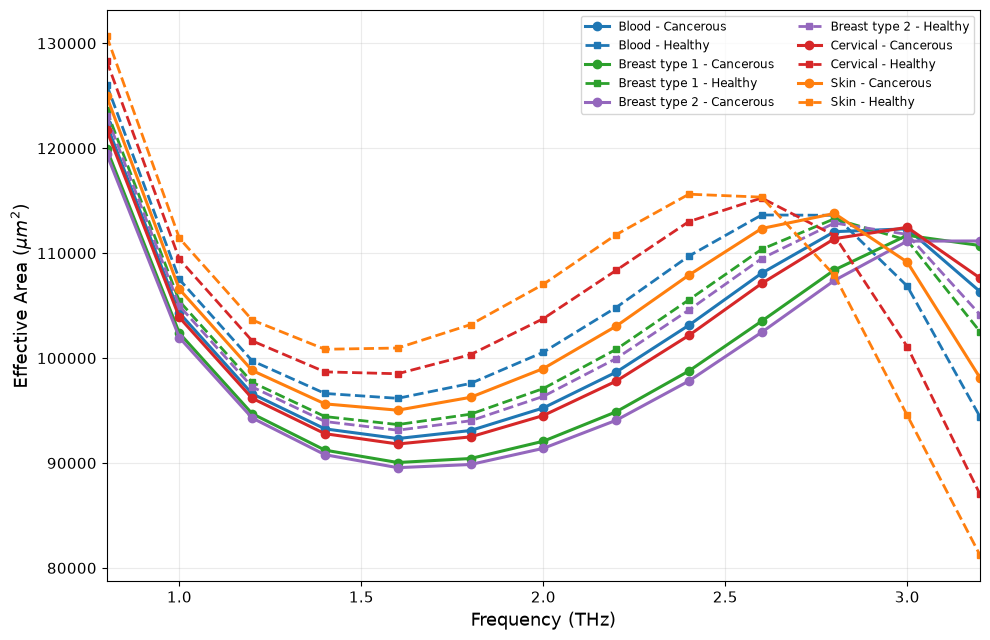

In [6]:
plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    # Convert m^2 to µm^2
    cancer_aeff = cancer["Aeff (m^2)"] * 1e12
    healthy_aeff = healthy["Aeff (m^2)"] * 1e12

    plt.plot(
        cancer["Frequency (THz)"],
        cancer_aeff,
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy_aeff,
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"Effective Area ($\mu m^2$)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=8.5,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Effective_Area_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Effective_Area_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

In [7]:
check = df[
    df["Frequency (THz)"].isin([2.6, 2.8, 3.0, 3.2])
][[
    "Cell type",
    "Status",
    "Frequency (THz)",
    "Re(neff)",
    "Aeff (m^2)",
    "Pfrac",
    "RS (%)"
]].copy()

check["Aeff (um^2)"] = check["Aeff (m^2)"] * 1e12

display(
    check.sort_values(
        ["Cell type", "Status", "Frequency (THz)"]
    )
)

,Cell type,Status,Frequency (THz),Re(neff),Aeff (m^2),Pfrac,RS (%),Aeff (um^2)
22,Blood,Cancerous,2.6,1.3851,1.080900e-07,0.821741,82.464852,108090.0
23,Blood,Cancerous,2.8,1.3881,1.120500e-07,0.789079,79.015879,112050.0
24,Blood,Cancerous,3.0,1.3911,1.123200e-07,0.746188,74.559754,112320.0
25,Blood,Cancerous,3.2,1.3942,1.063400e-07,0.693257,69.116894,106340.0
9,Blood,Healthy,2.6,1.3739,1.136400e-07,0.781469,78.266369,113640.0
10,Blood,Healthy,2.8,1.3775,1.136100e-07,0.736943,73.614059,113610.0
11,Blood,Healthy,3.0,1.3811,1.068600e-07,0.681615,67.909801,106860.0
12,Blood,Healthy,3.2,1.3851,9.440100e-08,0.619137,61.506935,94401.0
48,Breast type 1,Cancerous,2.6,1.3926,1.035200e-07,0.843842,84.771977,103520.0
49,Breast type 1,Cancerous,2.8,1.3953,1.084000e-07,0.818075,82.024452,108400.0


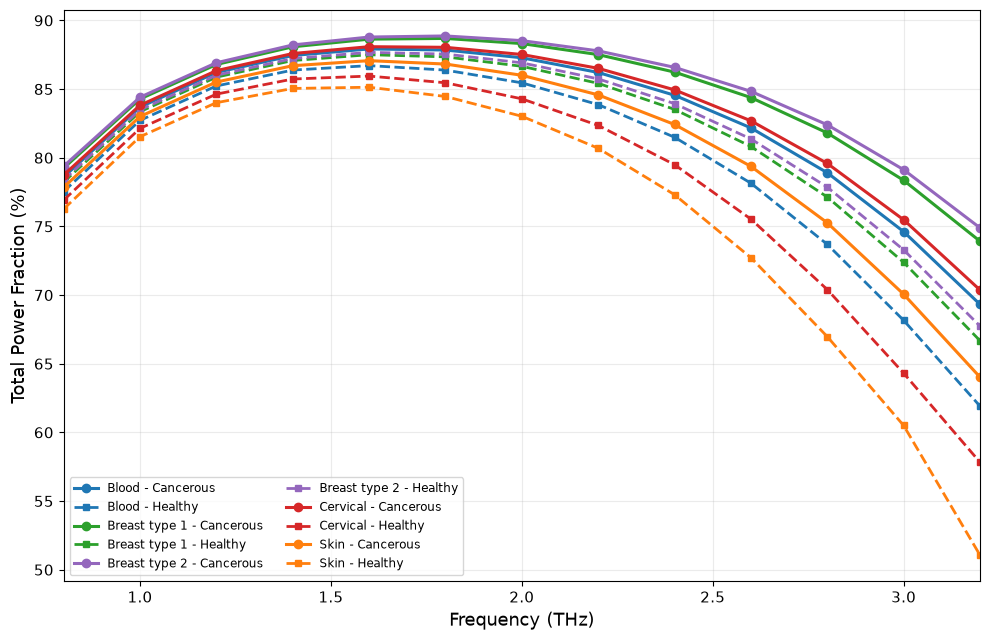

In [8]:
plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["TPF (%)"],
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy["TPF (%)"],
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Total Power Fraction (%)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=8.5,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Total_Power_Fraction_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Total_Power_Fraction_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

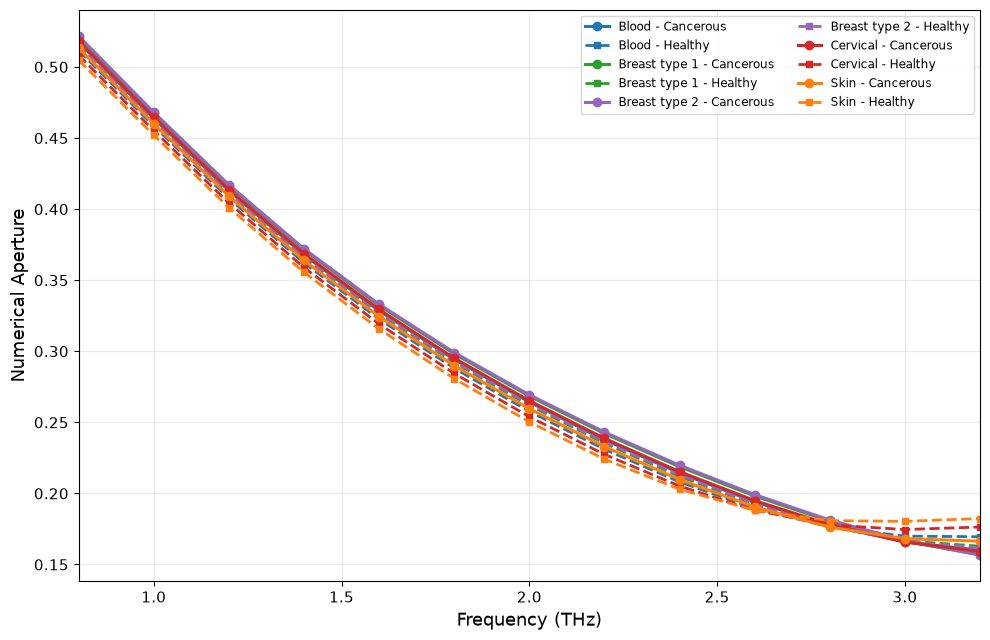

In [9]:
plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["NA"],
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy["NA"],
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Numerical Aperture", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=8.5,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Numerical_Aperture_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Numerical_Aperture_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

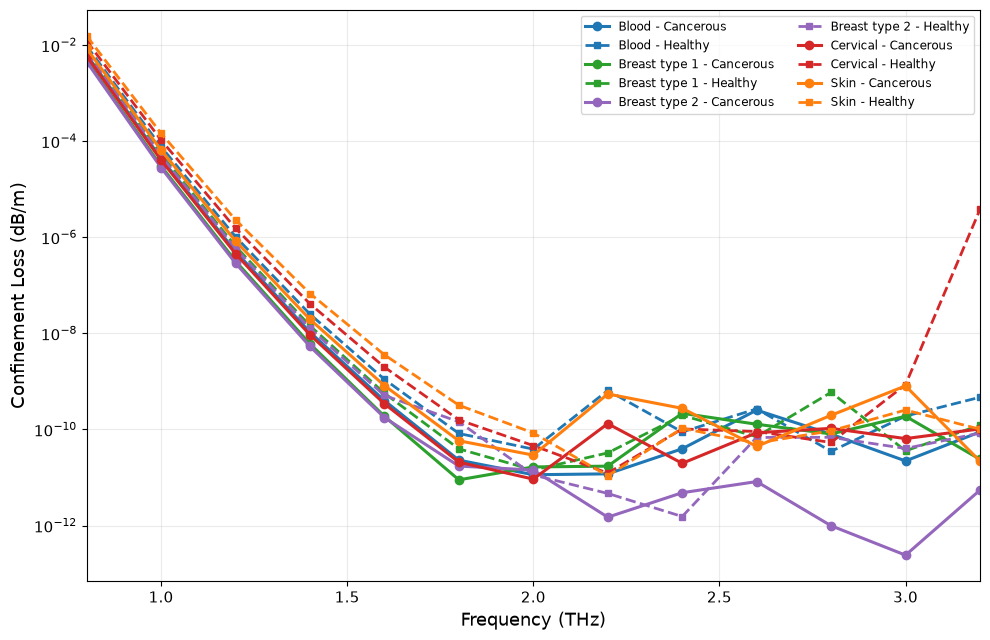

In [10]:
plt.figure(figsize=(10, 6.5))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)")

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)")

    plt.semilogy(
        cancer["Frequency (THz)"],
        cancer["CL (dB/m)"],
        color=colors[cell],
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=f"{cell} - Cancerous"
    )

    plt.semilogy(
        healthy["Frequency (THz)"],
        healthy["CL (dB/m)"],
        color=colors[cell],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{cell} - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Confinement Loss (dB/m)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)

plt.grid(
    True,
    which="both",
    alpha=0.25
)

plt.legend(
    fontsize=8.5,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Confinement_Loss_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Confinement_Loss_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

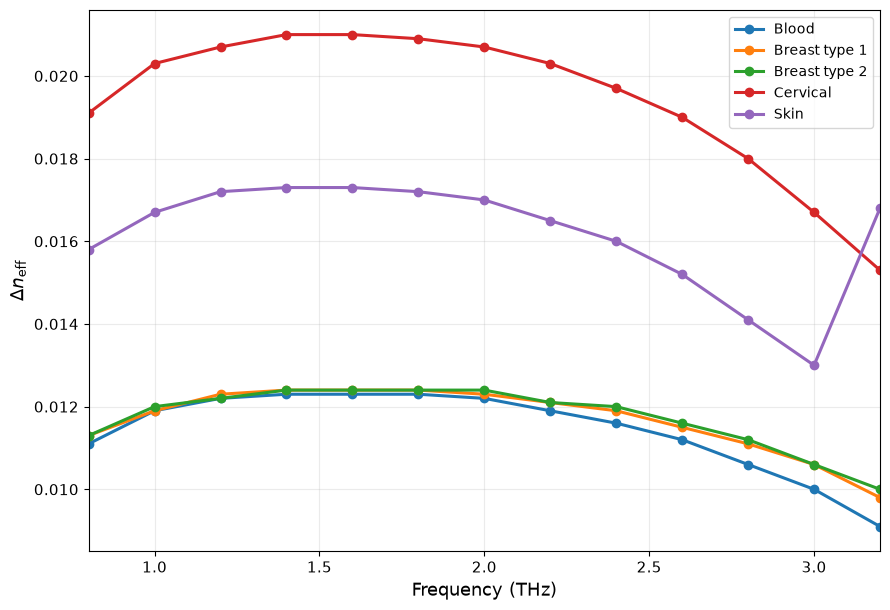

In [11]:
plt.figure(figsize=(9, 6.2))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    delta_neff = abs(
        cancer["Re(neff)"].values -
        healthy["Re(neff)"].values
    )

    plt.plot(
        cancer["Frequency (THz)"],
        delta_neff,
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=cell
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"$\Delta n_{\mathrm{eff}}$", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Delta_neff_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Delta_neff_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

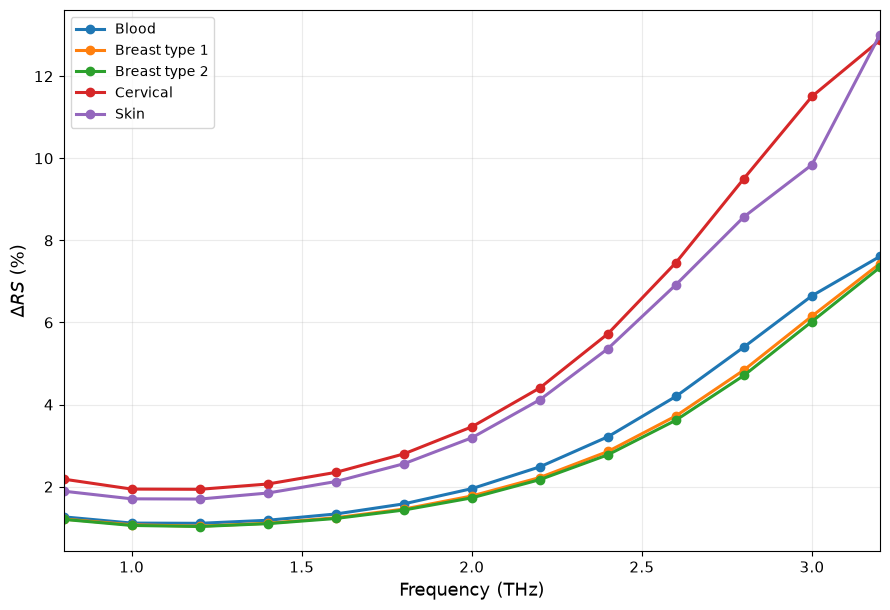

In [12]:
plt.figure(figsize=(9, 6.2))

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    delta_rs = abs(
        cancer["RS (%)"].values -
        healthy["RS (%)"].values
    )

    plt.plot(
        cancer["Frequency (THz)"],
        delta_rs,
        marker="o",
        linewidth=2.2,
        markersize=6,
        label=cell
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"$\Delta RS$ (%)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Delta_RS_vs_Frequency.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Delta_RS_vs_Frequency.pdf",
    bbox_inches="tight"
)

plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def read_comsol_excel(filename):
    df = pd.read_excel(
        filename,
        sheet_name=0,
        header=3
    )

    df = df.rename(columns={
        "f0 (THz)": "Frequency (THz)",
        "Real neff (1)": "Re(neff)",
        "Imag neff (1)": "Im(neff)",
        "Pcore (W)": "Pcore",
        "Ptotal (W)": "Ptotal",
        "Aeff (m^2)": "Aeff"
    })

    return df

d340_c = read_comsol_excel("D340_breast2_cancer_RI_1.401.xlsx")
d340_h = read_comsol_excel("D340_breast2_healthy_RI_1.387.xlsx")

d380_c = read_comsol_excel("D380_breast2_cancer_RI_1.401.xlsx")
d380_h = read_comsol_excel("D380_breast2_healthy_RI_1.387.xlsx")

print("340 cancer:", d340_c.shape)
print("340 healthy:", d340_h.shape)
print("380 cancer:", d380_c.shape)
print("380 healthy:", d380_h.shape)

340 cancer: (13, 7)
340 healthy: (13, 7)
380 cancer: (13, 7)
380 healthy: (13, 7)


In [3]:
na_cancer = 1.401
na_healthy = 1.387

def calculate_metrics(data, na):
    data = data.copy()

    data["Pfrac"] = data["Pcore"] / data["Ptotal"]

    data["TPF (%)"] = data["Pfrac"] * 100

    data["RS (%)"] = (
        na / data["Re(neff)"]
        * data["Pfrac"]
        * 100
    )

    data["Aeff (um^2)"] = data["Aeff"] * 1e12

    return data


d340_c = calculate_metrics(d340_c, na_cancer)
d340_h = calculate_metrics(d340_h, na_healthy)

d380_c = calculate_metrics(d380_c, na_cancer)
d380_h = calculate_metrics(d380_h, na_healthy)

print("Diameter-study metrics calculated successfully.")

Diameter-study metrics calculated successfully.


In [4]:
print("D340 Breast Type 2 - Cancerous")
display(d340_c)

print("D340 Breast Type 2 - Healthy")
display(d340_h)

print("D380 Breast Type 2 - Cancerous")
display(d380_c)

print("D380 Breast Type 2 - Healthy")
display(d380_h)

D340 Breast Type 2 - Cancerous


,Frequency (THz),lambda,Re(neff),Im(neff),Pcore,Ptotal,Aeff,Pfrac,TPF (%),RS (%),Aeff (um^2)
0,0.8,1.2822,1.2822,-3.652400e-08,5.144400e-08,6.674100e-08,1.142800e-07,0.770801,77.080056,84.221774,114280.0
1,1.0,1.3202,1.3202,-1.660000e-10,7.307300e-08,8.840800e-08,9.595100e-08,0.826543,82.654285,87.712962,95951.0
2,1.2,1.3434,1.3434,-1.311000e-12,9.830600e-08,1.150300e-07,8.798900e-08,0.854612,85.461184,89.125442,87989.0
3,1.4,1.3586,1.3586,-1.939700e-14,1.260000e-07,1.449600e-07,8.429500e-08,0.869205,86.920530,89.633198,84295.0
4,1.6,1.3691,1.3691,-4.787600e-16,1.548100e-07,1.767400e-07,8.287300e-08,0.875919,87.591943,89.632833,82873.0
5,1.8,1.3767,1.3767,-3.865600e-17,1.831200e-07,2.087400e-07,8.294300e-08,0.877264,87.726358,89.274808,82943.0
6,2.0,1.3824,1.3824,-5.579200e-19,2.090200e-07,2.391300e-07,8.417800e-08,0.874085,87.408523,88.584592,84178.0
7,2.2,1.3870,1.3870,1.576500e-16,2.304400e-07,2.658600e-07,8.644300e-08,0.866772,86.677199,87.552095,86443.0
8,2.4,1.3907,1.3907,1.496700e-16,2.453000e-07,2.869500e-07,8.965300e-08,0.854853,85.485276,86.118409,89653.0
9,2.6,1.3938,1.3938,4.625800e-16,2.519000e-07,3.007600e-07,9.363000e-08,0.837545,83.754489,84.187142,93630.0


D340 Breast Type 2 - Healthy


,Frequency (THz),lambda,Re(neff),Im(neff),Pcore,Ptotal,Aeff,Pfrac,TPF (%),RS (%),Aeff (um^2)
0,0.8,1.2712,1.2712,-5.542300e-08,5.148600e-08,6.772800e-08,1.177900e-07,0.760188,76.018781,82.943714,117790.0
1,1.0,1.3085,1.3085,-2.904700e-10,7.242800e-08,8.867000e-08,9.884400e-08,0.816826,81.682644,86.582978,98844.0
2,1.2,1.3314,1.3314,-2.661100e-12,9.656400e-08,1.142900e-07,9.078100e-08,0.844903,84.490332,88.018695,90781.0
3,1.4,1.3464,1.3464,-4.599100e-14,1.225800e-07,1.427300e-07,8.724300e-08,0.858824,85.882435,88.472176,87243.0
4,1.6,1.3569,1.3569,-1.413700e-15,1.489100e-07,1.723100e-07,8.616400e-08,0.864198,86.419825,88.336869,86164.0
5,1.8,1.3645,1.3645,-7.714000e-17,1.737300e-07,2.011900e-07,8.674500e-08,0.863512,86.351210,87.775103,86745.0
6,2.0,1.3703,1.3703,1.528800e-18,1.949300e-07,2.273400e-07,8.864900e-08,0.857438,85.743820,86.788789,88649.0
7,2.2,1.3750,1.3750,-6.068800e-17,2.103700e-07,2.486900e-07,9.169400e-08,0.845913,84.591258,85.329509,91694.0
8,2.4,1.3789,1.3789,-1.889600e-16,2.182100e-07,2.634600e-07,9.562900e-08,0.828247,82.824717,83.311250,95629.0
9,2.6,1.3823,1.3823,3.189800e-16,2.174300e-07,2.706900e-07,9.982800e-08,0.803244,80.324356,80.597470,99828.0


D380 Breast Type 2 - Cancerous


,Frequency (THz),lambda,Re(neff),Im(neff),Pcore,Ptotal,Aeff,Pfrac,TPF (%),RS (%),Aeff (um^2)
0,0.8,1.2970,1.2970,-2.763300e-08,6.497800e-08,7.983100e-08,1.251100e-07,0.813944,81.394446,87.921063,125110.0
1,1.0,1.3308,1.3308,-1.500200e-10,9.346800e-08,1.087700e-07,1.082700e-07,0.859318,85.931783,90.464704,108270.0
2,1.2,1.3512,1.3512,-1.394000e-12,1.266400e-07,1.436000e-07,1.008800e-07,0.881894,88.189415,91.439735,100880.0
3,1.4,1.3644,1.3644,-2.366700e-14,1.631200e-07,1.825800e-07,9.755700e-08,0.893417,89.341658,91.738246,97557.0
4,1.6,1.3735,1.3735,-6.925900e-16,2.011800e-07,2.239400e-07,9.650600e-08,0.898366,89.836563,91.635257,96506.0
5,1.8,1.3800,1.3800,-5.244600e-17,2.387000e-07,2.655900e-07,9.703800e-08,0.898754,89.875372,91.243041,97038.0
6,2.0,1.3849,1.3849,-2.138300e-17,2.730700e-07,3.050500e-07,9.888800e-08,0.895165,89.516473,90.557136,98888.0
7,2.2,1.3888,1.3888,-1.013800e-16,3.013300e-07,3.394700e-07,1.019800e-07,0.887648,88.764839,89.544600,101980.0
8,2.4,1.3920,1.3920,-1.865300e-16,3.204400e-07,3.659400e-07,1.063000e-07,0.875663,87.566268,88.132429,106300.0
9,2.6,1.3948,1.3948,-7.336900e-16,3.278200e-07,3.820400e-07,1.116600e-07,0.858078,85.807769,86.189191,111660.0


D380 Breast Type 2 - Healthy


,Frequency (THz),lambda,Re(neff),Im(neff),Pcore,Ptotal,Aeff,Pfrac,TPF (%),RS (%),Aeff (um^2)
0,0.8,1.2854,1.2854,-4.230300e-08,6.485600e-08,8.062900e-08,1.287900e-07,0.804376,80.437560,86.795469,128790.0
1,1.0,1.3186,1.3186,-2.636400e-10,9.245900e-08,1.086900e-07,1.114300e-07,0.850667,85.066703,89.479385,111430.0
2,1.2,1.3388,1.3388,-2.832500e-12,1.242200e-07,1.422500e-07,1.040100e-07,0.873251,87.325132,90.469045,104010.0
3,1.4,1.3518,1.3518,-5.620300e-14,1.585000e-07,1.792900e-07,1.009400e-07,0.884043,88.404261,90.706251,100940.0
4,1.6,1.3609,1.3609,-2.016800e-15,1.933200e-07,2.177600e-07,1.003600e-07,0.887766,88.776635,90.479236,100360.0
5,1.8,1.3674,1.3674,-1.251400e-16,2.261600e-07,2.552400e-07,1.015800e-07,0.886068,88.606801,89.876871,101580.0
6,2.0,1.3725,1.3725,-6.864300e-18,2.541200e-07,2.889300e-07,1.043400e-07,0.879521,87.952099,88.881283,104340.0
7,2.2,1.3765,1.3765,1.147300e-16,2.740800e-07,3.158700e-07,1.085400e-07,0.867699,86.769874,87.431758,108540.0
8,2.4,1.3799,1.3799,-3.040100e-15,2.832900e-07,3.334900e-07,1.139200e-07,0.849471,84.947075,85.384153,113920.0
9,2.6,1.3830,1.3830,-1.669400e-15,2.802200e-07,3.404100e-07,1.195900e-07,0.823184,82.318381,82.556467,119590.0


In [5]:
d340_c.to_excel(
    "D340_Breast2_Cancer_Processed.xlsx",
    index=False
)

d340_h.to_excel(
    "D340_Breast2_Healthy_Processed.xlsx",
    index=False
)

d380_c.to_excel(
    "D380_Breast2_Cancer_Processed.xlsx",
    index=False
)

d380_h.to_excel(
    "D380_Breast2_Healthy_Processed.xlsx",
    index=False
)

print("Processed diameter-study Excel files saved successfully.")

Processed diameter-study Excel files saved successfully.


In [7]:
import pandas as pd

# Reload the finalized 360 µm baseline workbook
baseline_file = "THz_PCF_Baseline_Postprocessed.xlsx"

df = pd.read_excel(
    baseline_file,
    sheet_name="Master_Data"
)

print("Baseline workbook loaded successfully.")
print("Shape:", df.shape)
print(df.columns.tolist())

Baseline workbook loaded successfully.
Shape: (130, 14)
['Cell type', 'Status', 'RI', 'Frequency (THz)', 'Re(neff)', 'Im(neff)', 'Pcore (W)', 'Ptotal (W)', 'Aeff (m^2)', 'Pfrac', 'TPF (%)', 'RS (%)', 'CL (dB/m)', 'NA']


In [8]:
# Extract existing 360 µm Breast Type 2 data

d360_c = df[
    (df["Cell type"] == "Breast type 2") &
    (df["Status"] == "Cancerous")
].sort_values("Frequency (THz)").copy()

d360_h = df[
    (df["Cell type"] == "Breast type 2") &
    (df["Status"] == "Healthy")
].sort_values("Frequency (THz)").copy()

print("360 µm cancer data:", d360_c.shape)
print("360 µm healthy data:", d360_h.shape)

display(d360_c.head())
display(d360_h.head())

360 µm cancer data: (13, 14)
360 µm healthy data: (13, 14)


,Cell type,Status,RI,Frequency (THz),Re(neff),Im(neff),Pcore (W),Ptotal (W),Aeff (m^2),Pfrac,TPF (%),RS (%),CL (dB/m),NA
65,Breast type 2,Cancerous,1.401,0.8,1.2899,-3.118400e-08,5.856600e-08,7.377700e-08,1.194700e-07,0.793825,79.382463,86.219731,4.541515e-03,0.521805
66,Breast type 2,Cancerous,1.401,1.0,1.3258,-1.549100e-10,8.380800e-08,9.929100e-08,1.019500e-07,0.844064,84.406442,89.194015,2.820061e-05,0.468105
67,Breast type 2,Cancerous,1.401,1.2,1.3475,-1.328300e-12,1.132000e-07,1.302400e-07,9.429200e-08,0.869165,86.916462,90.367320,2.901726e-07,0.417167
68,Breast type 2,Cancerous,1.401,1.4,1.3617,-2.094500e-14,1.454800e-07,1.649200e-07,9.079100e-08,0.882125,88.212467,90.758365,5.338108e-09,0.372155
69,Breast type 2,Cancerous,1.401,1.6,1.3714,-6.074400e-16,1.790900e-07,2.017000e-07,8.955800e-08,0.887903,88.790283,90.706713,1.769304e-10,0.333073


,Cell type,Status,RI,Frequency (THz),Re(neff),Im(neff),Pcore (W),Ptotal (W),Aeff (m^2),Pfrac,TPF (%),RS (%),CL (dB/m),NA
52,Breast type 2,Healthy,1.387,0.8,1.2786,-4.756700e-08,5.851700e-08,7.466500e-08,1.230600e-07,0.783727,78.372732,85.017190,6.927471e-03,0.516192
53,Breast type 2,Healthy,1.387,1.0,1.3138,-2.718600e-10,8.296100e-08,9.936900e-08,1.049700e-07,0.834878,83.487808,88.139435,4.949078e-05,0.462783
54,Breast type 2,Healthy,1.387,1.2,1.3353,-2.699400e-12,1.110800e-07,1.291500e-07,9.725200e-08,0.860085,86.008517,89.338586,5.896950e-07,0.411861
55,Breast type 2,Healthy,1.387,1.4,1.3493,-4.982100e-14,1.413800e-07,1.620900e-07,9.395400e-08,0.872231,87.223148,89.660198,1.269754e-08,0.366693
56,Breast type 2,Healthy,1.387,1.6,1.3590,-1.754300e-15,1.720900e-07,1.962800e-07,9.312700e-08,0.876758,87.675769,89.482187,5.109787e-10,0.327325


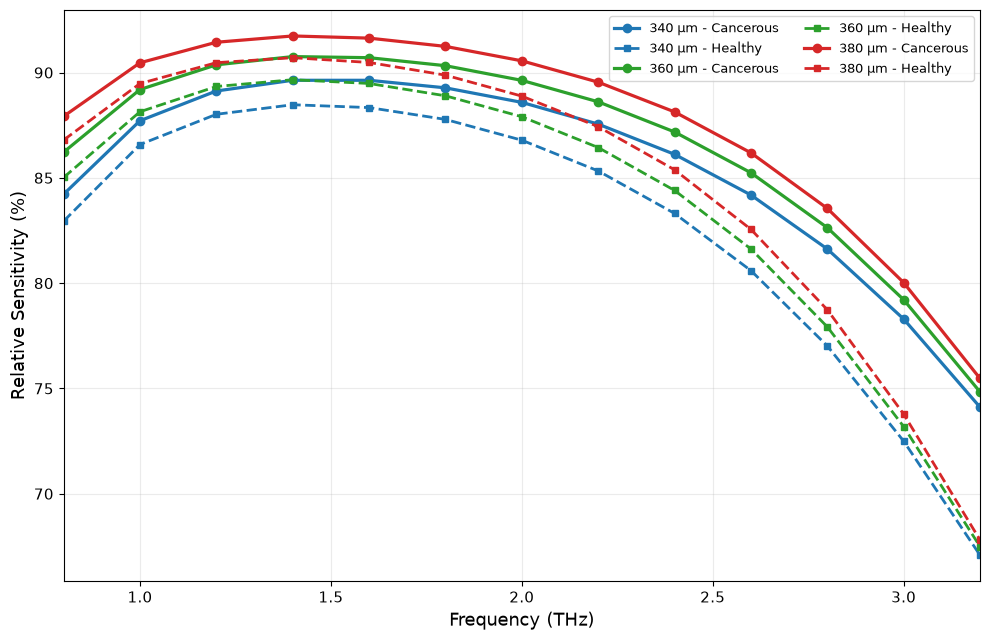

In [9]:
plt.figure(figsize=(10, 6.5))

diameter_data = {
    340: (d340_c, d340_h),
    360: (d360_c, d360_h),
    380: (d380_c, d380_h)
}

diameter_colors = {
    340: "tab:blue",
    360: "tab:green",
    380: "tab:red"
}

for diameter, (cancer, healthy) in diameter_data.items():

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["RS (%)"],
        color=diameter_colors[diameter],
        marker="o",
        linewidth=2.3,
        markersize=6,
        label=f"{diameter} µm - Cancerous"
    )

    plt.plot(
        healthy["Frequency (THz)"],
        healthy["RS (%)"],
        color=diameter_colors[diameter],
        marker="s",
        linestyle="--",
        linewidth=2.0,
        markersize=5,
        label=f"{diameter} µm - Healthy"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Relative Sensitivity (%)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=9,
    ncol=2,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Core_Diameter_RS_Comparison.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Core_Diameter_RS_Comparison.pdf",
    bbox_inches="tight"
)

plt.show()

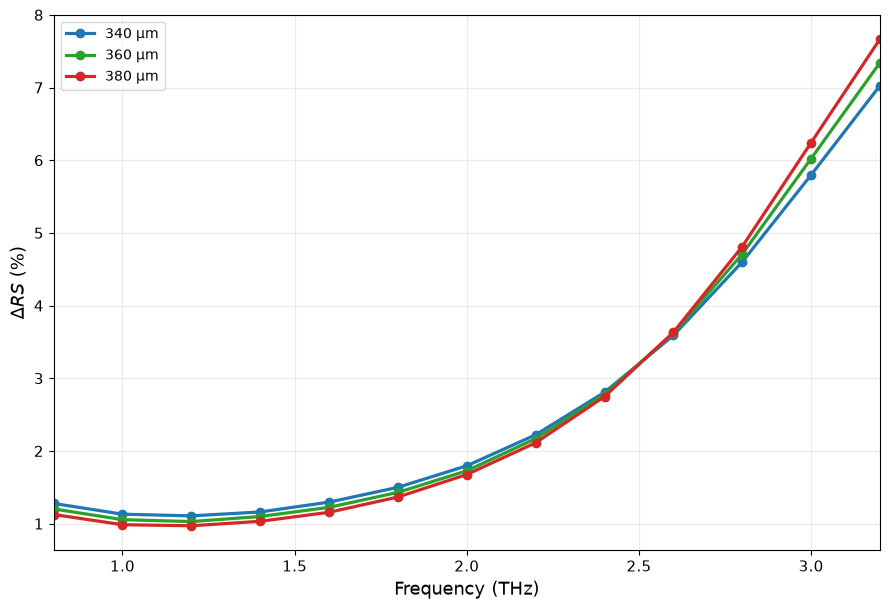

In [10]:
plt.figure(figsize=(9, 6.2))

diameter_pairs = {
    340: (d340_c, d340_h),
    360: (d360_c, d360_h),
    380: (d380_c, d380_h)
}

diameter_colors = {
    340: "tab:blue",
    360: "tab:green",
    380: "tab:red"
}

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values("Frequency (THz)").reset_index(drop=True)
    healthy = healthy.sort_values("Frequency (THz)").reset_index(drop=True)

    delta_rs = abs(
        cancer["RS (%)"].values -
        healthy["RS (%)"].values
    )

    plt.plot(
        cancer["Frequency (THz)"],
        delta_rs,
        color=diameter_colors[diameter],
        marker="o",
        linewidth=2.3,
        markersize=6,
        label=f"{diameter} µm"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"$\Delta RS$ (%)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Core_Diameter_Delta_RS.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Core_Diameter_Delta_RS.pdf",
    bbox_inches="tight"
)

plt.show()

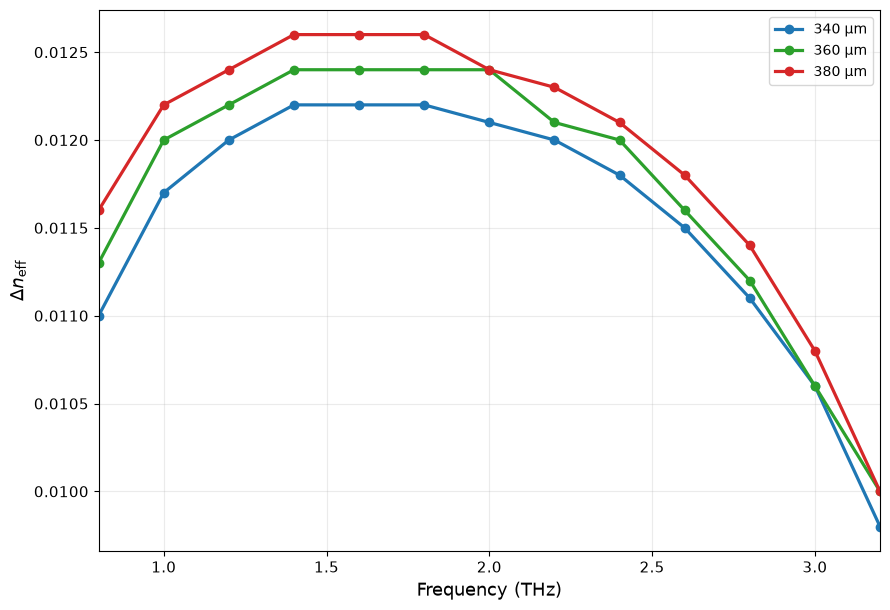

In [11]:
plt.figure(figsize=(9, 6.2))

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    healthy = healthy.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    delta_neff = abs(
        cancer["Re(neff)"].values -
        healthy["Re(neff)"].values
    )

    plt.plot(
        cancer["Frequency (THz)"],
        delta_neff,
        color=diameter_colors[diameter],
        marker="o",
        linewidth=2.3,
        markersize=6,
        label=f"{diameter} µm"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"$\Delta n_{\mathrm{eff}}$", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Core_Diameter_Delta_neff.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Core_Diameter_Delta_neff.pdf",
    bbox_inches="tight"
)

plt.show()

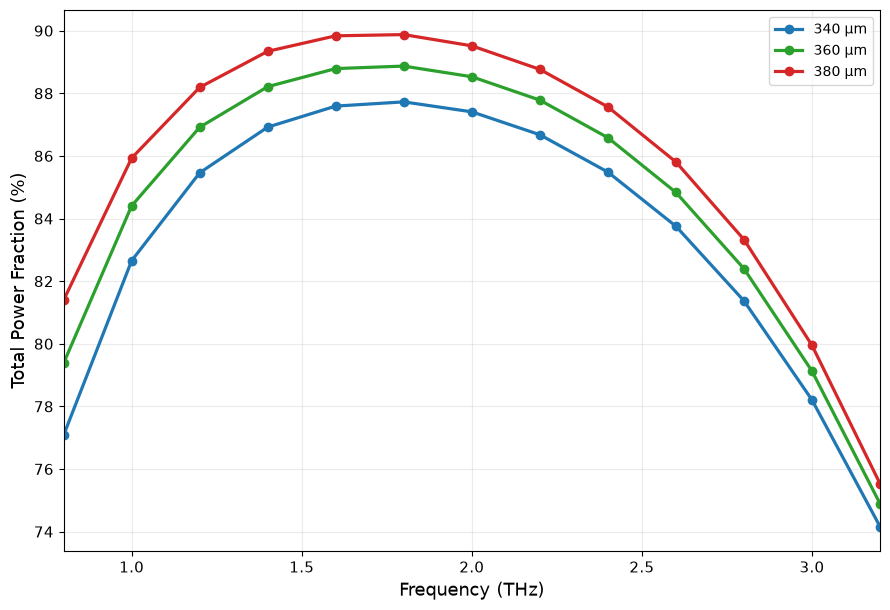

In [12]:
plt.figure(figsize=(9, 6.2))

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    plt.plot(
        cancer["Frequency (THz)"],
        cancer["TPF (%)"],
        color=diameter_colors[diameter],
        marker="o",
        linewidth=2.3,
        markersize=6,
        label=f"{diameter} µm"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Total Power Fraction (%)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Core_Diameter_TPF.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Core_Diameter_TPF.pdf",
    bbox_inches="tight"
)

plt.show()

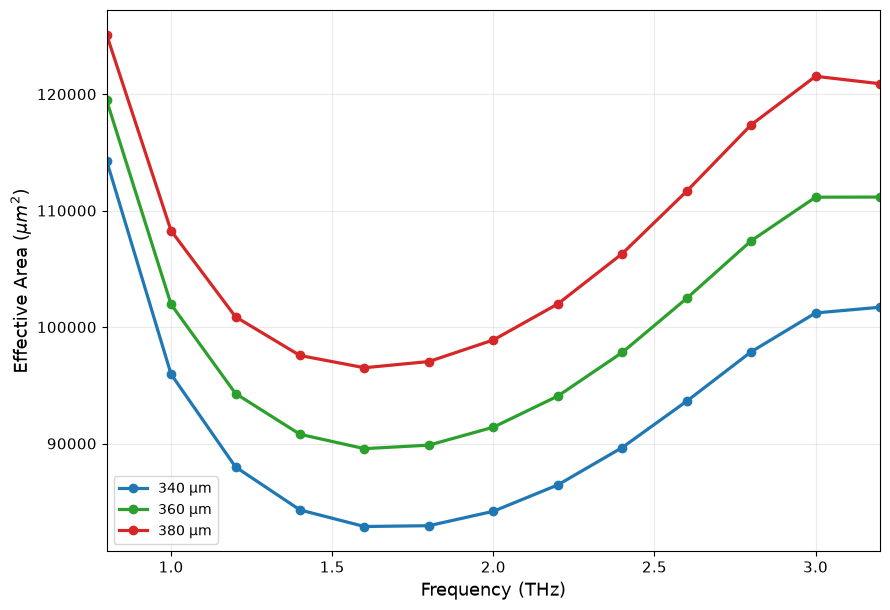

In [13]:
plt.figure(figsize=(9, 6.2))

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    # 360 µm data store Aeff as "Aeff (m^2)"
    # 340/380 processed data store converted Aeff as "Aeff (um^2)"
    if "Aeff (um^2)" in cancer.columns:
        aeff_um2 = cancer["Aeff (um^2)"]
    else:
        aeff_um2 = cancer["Aeff (m^2)"] * 1e12

    plt.plot(
        cancer["Frequency (THz)"],
        aeff_um2,
        color=diameter_colors[diameter],
        marker="o",
        linewidth=2.3,
        markersize=6,
        label=f"{diameter} µm"
    )

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel(r"Effective Area ($\mu m^2$)", fontsize=13)

plt.xlim(0.8, 3.2)

plt.tick_params(axis="both", labelsize=11)
plt.grid(True, alpha=0.25)

plt.legend(
    fontsize=10,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "Figures/Core_Diameter_Effective_Area.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Core_Diameter_Effective_Area.pdf",
    bbox_inches="tight"
)

plt.show()

In [14]:
summary_rows = []

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values("Frequency (THz)").reset_index(drop=True)
    healthy = healthy.sort_values("Frequency (THz)").reset_index(drop=True)

    for f in [1.4, 3.2]:

        c = cancer[np.isclose(cancer["Frequency (THz)"], f)].iloc[0]
        h = healthy[np.isclose(healthy["Frequency (THz)"], f)].iloc[0]

        if "Aeff (um^2)" in cancer.columns:
            aeff = c["Aeff (um^2)"]
        else:
            aeff = c["Aeff (m^2)"] * 1e12

        summary_rows.append({
            "Core diameter (µm)": diameter,
            "Frequency (THz)": f,
            "Cancer RS (%)": c["RS (%)"],
            "Healthy RS (%)": h["RS (%)"],
            "Delta RS (%)": abs(c["RS (%)"] - h["RS (%)"]),
            "Delta neff": abs(c["Re(neff)"] - h["Re(neff)"]),
            "Cancer TPF (%)": c["TPF (%)"],
            "Cancer Aeff (µm²)": aeff
        })

summary = pd.DataFrame(summary_rows)

display(summary.round({
    "Cancer RS (%)": 3,
    "Healthy RS (%)": 3,
    "Delta RS (%)": 3,
    "Delta neff": 5,
    "Cancer TPF (%)": 3,
    "Cancer Aeff (µm²)": 1
}))

summary.to_excel(
    "Core_Diameter_Optimization_Summary.xlsx",
    index=False
)

print("Optimization summary saved successfully.")

,Core diameter (µm),Frequency (THz),Cancer RS (%),Healthy RS (%),Delta RS (%),Delta neff,Cancer TPF (%),Cancer Aeff (µm²)
0,340,1.4,89.633,88.472,1.161,0.0122,86.921,84295.0
1,340,3.2,74.111,67.084,7.027,0.0098,74.164,101700.0
2,360,1.4,90.758,89.660,1.098,0.0124,88.212,90791.0
3,360,3.2,74.837,67.494,7.343,0.0100,74.895,111160.0
4,380,1.4,91.738,90.706,1.032,0.0126,89.342,97557.0
5,380,3.2,75.474,67.806,7.668,0.0100,75.533,120890.0


Optimization summary saved successfully.


In [15]:
comparison = pd.DataFrame({
    "Frequency (THz)": d360_c["Frequency (THz)"].values,

    "RS_360": d360_c["RS (%)"].values,
    "RS_380": d380_c["RS (%)"].values,

    "TPF_360": d360_c["TPF (%)"].values,
    "TPF_380": d380_c["TPF (%)"].values,

    "DeltaRS_360": abs(
        d360_c["RS (%)"].values -
        d360_h["RS (%)"].values
    ),

    "DeltaRS_380": abs(
        d380_c["RS (%)"].values -
        d380_h["RS (%)"].values
    ),

    "DeltaNeff_360": abs(
        d360_c["Re(neff)"].values -
        d360_h["Re(neff)"].values
    ),

    "DeltaNeff_380": abs(
        d380_c["Re(neff)"].values -
        d380_h["Re(neff)"].values
    )
})

comparison["RS improvement (%)"] = (
    (comparison["RS_380"] - comparison["RS_360"])
    / comparison["RS_360"] * 100
)

comparison["TPF improvement (%)"] = (
    (comparison["TPF_380"] - comparison["TPF_360"])
    / comparison["TPF_360"] * 100
)

comparison["DeltaRS improvement (%)"] = (
    (comparison["DeltaRS_380"] - comparison["DeltaRS_360"])
    / comparison["DeltaRS_360"] * 100
)

comparison["DeltaNeff improvement (%)"] = (
    (comparison["DeltaNeff_380"] - comparison["DeltaNeff_360"])
    / comparison["DeltaNeff_360"] * 100
)

display(comparison.round(4))

comparison.to_excel(
    "Baseline_360_vs_Optimized_380.xlsx",
    index=False
)

print("Final baseline-vs-optimized comparison saved.")

,Frequency (THz),RS_360,RS_380,TPF_360,TPF_380,DeltaRS_360,DeltaRS_380,DeltaNeff_360,DeltaNeff_380,RS improvement (%),TPF improvement (%),DeltaRS improvement (%),DeltaNeff improvement (%)
0,0.8,86.2197,87.9211,79.3825,81.3944,1.2025,1.1256,0.0113,0.0116,1.9733,2.5345,-6.3987,2.6549
1,1.0,89.1940,90.4647,84.4064,85.9318,1.0546,0.9853,0.0120,0.0122,1.4246,1.8071,-6.5677,1.6667
2,1.2,90.3673,91.4397,86.9165,88.1894,1.0287,0.9707,0.0122,0.0124,1.1867,1.4646,-5.6423,1.6393
3,1.4,90.7584,91.7382,88.2125,89.3417,1.0982,1.0320,0.0124,0.0126,1.0797,1.2801,-6.0256,1.6129
4,1.6,90.7067,91.6353,88.7903,89.8366,1.2245,1.1560,0.0124,0.0126,1.0237,1.1784,-5.5944,1.6129
5,1.8,90.3264,91.2430,88.8693,89.8754,1.4298,1.3662,0.0124,0.0126,1.0148,1.1320,-4.4530,1.6129
6,2.0,89.6296,90.5571,88.5293,89.5165,1.7272,1.6759,0.0124,0.0124,1.0348,1.1151,-2.9715,0.0000
7,2.2,88.6116,89.5446,87.7830,88.7648,2.1705,2.1128,0.0121,0.0123,1.0530,1.1185,-2.6586,1.6529
8,2.4,87.1805,88.1324,86.5831,87.5663,2.7761,2.7483,0.0120,0.0121,1.0919,1.1355,-1.0025,0.8333
9,2.6,85.2425,86.1892,84.8349,85.8078,3.6187,3.6327,0.0116,0.0118,1.1106,1.1468,0.3871,1.7241


Final baseline-vs-optimized comparison saved.


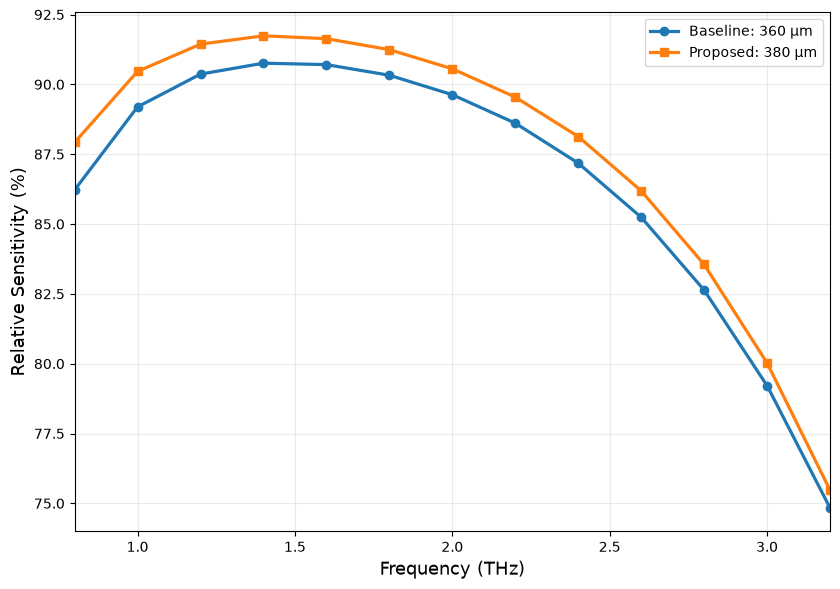

In [16]:
plt.figure(figsize=(8.5, 6))

plt.plot(
    d360_c["Frequency (THz)"],
    d360_c["RS (%)"],
    marker="o",
    linewidth=2.3,
    label="Baseline: 360 µm"
)

plt.plot(
    d380_c["Frequency (THz)"],
    d380_c["RS (%)"],
    marker="s",
    linewidth=2.3,
    label="Proposed: 380 µm"
)

plt.xlabel("Frequency (THz)", fontsize=13)
plt.ylabel("Relative Sensitivity (%)", fontsize=13)

plt.xlim(0.8, 3.2)
plt.grid(True, alpha=0.25)
plt.legend(fontsize=10)

plt.tight_layout()

plt.savefig(
    "Figures/Baseline_vs_Optimized_RS.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Figures/Baseline_vs_Optimized_RS.pdf",
    bbox_inches="tight"
)

plt.show()

In [17]:
import pandas as pd
import numpy as np

# ============================================================
# FINAL THESIS RESULTS SUMMARY
# ============================================================

# ------------------------------------------------------------
# 1. LOAD FINAL BASELINE DATA
# ------------------------------------------------------------

baseline_file = "THz_PCF_Baseline_Postprocessed.xlsx"

df = pd.read_excel(
    baseline_file,
    sheet_name="Master_Data"
)

# Make sure rows are ordered properly
df = df.sort_values(
    ["Cell type", "Status", "Frequency (THz)"]
).reset_index(drop=True)


# ------------------------------------------------------------
# 2. BASELINE HEALTHY-CANCER SUMMARY FOR ALL 5 CELL TYPES
# ------------------------------------------------------------

cell_types = [
    "Blood",
    "Breast type 1",
    "Breast type 2",
    "Cervical",
    "Skin"
]

baseline_summary_rows = []

for cell in cell_types:

    cancer = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Cancerous")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    healthy = df[
        (df["Cell type"] == cell) &
        (df["Status"] == "Healthy")
    ].sort_values("Frequency (THz)").reset_index(drop=True)

    # --------------------------
    # Maximum cancerous RS
    # --------------------------
    idx_rs = cancer["RS (%)"].idxmax()

    max_cancer_rs = cancer.loc[idx_rs, "RS (%)"]
    freq_max_rs = cancer.loc[idx_rs, "Frequency (THz)"]

    # --------------------------
    # Maximum cancerous TPF
    # --------------------------
    idx_tpf = cancer["TPF (%)"].idxmax()

    max_cancer_tpf = cancer.loc[idx_tpf, "TPF (%)"]
    freq_max_tpf = cancer.loc[idx_tpf, "Frequency (THz)"]

    # --------------------------
    # Healthy-cancer differences
    # --------------------------
    delta_rs = np.abs(
        cancer["RS (%)"].values -
        healthy["RS (%)"].values
    )

    delta_neff = np.abs(
        cancer["Re(neff)"].values -
        healthy["Re(neff)"].values
    )

    # Maximum Delta RS
    idx_drs = np.argmax(delta_rs)

    max_delta_rs = delta_rs[idx_drs]
    freq_max_delta_rs = cancer.loc[
        idx_drs, "Frequency (THz)"
    ]

    # Maximum Delta neff
    idx_dneff = np.argmax(delta_neff)

    max_delta_neff = delta_neff[idx_dneff]
    freq_max_delta_neff = cancer.loc[
        idx_dneff, "Frequency (THz)"
    ]

    # --------------------------
    # Effective area at maximum RS
    # --------------------------
    aeff_at_max_rs = (
        cancer.loc[idx_rs, "Aeff (m^2)"] * 1e12
    )

    # --------------------------
    # Numerical aperture at max RS
    # --------------------------
    na_at_max_rs = cancer.loc[idx_rs, "NA"]

    baseline_summary_rows.append({

        "Cell type": cell,

        "Cancer RI":
            cancer["RI"].iloc[0],

        "Healthy RI":
            healthy["RI"].iloc[0],

        "Max cancer RS (%)":
            max_cancer_rs,

        "Frequency at max RS (THz)":
            freq_max_rs,

        "Max cancer TPF (%)":
            max_cancer_tpf,

        "Frequency at max TPF (THz)":
            freq_max_tpf,

        "Max Delta RS (%)":
            max_delta_rs,

        "Frequency at max Delta RS (THz)":
            freq_max_delta_rs,

        "Max Delta neff":
            max_delta_neff,

        "Frequency at max Delta neff (THz)":
            freq_max_delta_neff,

        "Aeff at max RS (um^2)":
            aeff_at_max_rs,

        "NA at max RS":
            na_at_max_rs
    })


baseline_summary = pd.DataFrame(
    baseline_summary_rows
)


# ------------------------------------------------------------
# 3. LOAD CORE-DIAMETER STUDY
# ------------------------------------------------------------

d340_c = pd.read_excel(
    "D340_Breast2_Cancer_Processed.xlsx"
)

d340_h = pd.read_excel(
    "D340_Breast2_Healthy_Processed.xlsx"
)

d380_c = pd.read_excel(
    "D380_Breast2_Cancer_Processed.xlsx"
)

d380_h = pd.read_excel(
    "D380_Breast2_Healthy_Processed.xlsx"
)

# Extract 360 µm Breast Type 2 from baseline
d360_c = df[
    (df["Cell type"] == "Breast type 2") &
    (df["Status"] == "Cancerous")
].sort_values("Frequency (THz)").reset_index(drop=True)

d360_h = df[
    (df["Cell type"] == "Breast type 2") &
    (df["Status"] == "Healthy")
].sort_values("Frequency (THz)").reset_index(drop=True)


diameter_pairs = {
    340: (d340_c, d340_h),
    360: (d360_c, d360_h),
    380: (d380_c, d380_h)
}


# ------------------------------------------------------------
# 4. CORE-DIAMETER OPTIMIZATION SUMMARY
# ------------------------------------------------------------

diameter_summary_rows = []

for diameter, (cancer, healthy) in diameter_pairs.items():

    cancer = cancer.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    healthy = healthy.sort_values(
        "Frequency (THz)"
    ).reset_index(drop=True)

    delta_rs = np.abs(
        cancer["RS (%)"].values -
        healthy["RS (%)"].values
    )

    delta_neff = np.abs(
        cancer["Re(neff)"].values -
        healthy["Re(neff)"].values
    )

    # Maximum cancer RS
    idx_rs = cancer["RS (%)"].idxmax()

    # Maximum TPF
    idx_tpf = cancer["TPF (%)"].idxmax()

    # Maximum Delta RS
    idx_drs = np.argmax(delta_rs)

    # Maximum Delta neff
    idx_dneff = np.argmax(delta_neff)

    # Handle Aeff column differences
    if "Aeff (um^2)" in cancer.columns:
        aeff = cancer["Aeff (um^2)"].values
    else:
        aeff = (
            cancer["Aeff (m^2)"].values * 1e12
        )

    diameter_summary_rows.append({

        "Core diameter (um)":
            diameter,

        "Maximum cancer RS (%)":
            cancer.loc[idx_rs, "RS (%)"],

        "Frequency at max RS (THz)":
            cancer.loc[
                idx_rs,
                "Frequency (THz)"
            ],

        "Maximum TPF (%)":
            cancer.loc[idx_tpf, "TPF (%)"],

        "Frequency at max TPF (THz)":
            cancer.loc[
                idx_tpf,
                "Frequency (THz)"
            ],

        "Maximum Delta RS (%)":
            delta_rs[idx_drs],

        "Frequency at max Delta RS (THz)":
            cancer.loc[
                idx_drs,
                "Frequency (THz)"
            ],

        "Maximum Delta neff":
            delta_neff[idx_dneff],

        "Frequency at max Delta neff (THz)":
            cancer.loc[
                idx_dneff,
                "Frequency (THz)"
            ],

        "Minimum Aeff (um^2)":
            np.min(aeff),

        "Maximum Aeff (um^2)":
            np.max(aeff)
    })


diameter_summary = pd.DataFrame(
    diameter_summary_rows
)


# ------------------------------------------------------------
# 5. DETAILED 360 vs 380 IMPROVEMENT
# ------------------------------------------------------------

comparison_rows = []

for f in d360_c["Frequency (THz)"].values:

    c360 = d360_c[
        np.isclose(
            d360_c["Frequency (THz)"],
            f
        )
    ].iloc[0]

    h360 = d360_h[
        np.isclose(
            d360_h["Frequency (THz)"],
            f
        )
    ].iloc[0]

    c380 = d380_c[
        np.isclose(
            d380_c["Frequency (THz)"],
            f
        )
    ].iloc[0]

    h380 = d380_h[
        np.isclose(
            d380_h["Frequency (THz)"],
            f
        )
    ].iloc[0]

    delta_rs_360 = abs(
        c360["RS (%)"] -
        h360["RS (%)"]
    )

    delta_rs_380 = abs(
        c380["RS (%)"] -
        h380["RS (%)"]
    )

    delta_neff_360 = abs(
        c360["Re(neff)"] -
        h360["Re(neff)"]
    )

    delta_neff_380 = abs(
        c380["Re(neff)"] -
        h380["Re(neff)"]
    )

    comparison_rows.append({

        "Frequency (THz)": f,

        "RS 360 (%)":
            c360["RS (%)"],

        "RS 380 (%)":
            c380["RS (%)"],

        "RS improvement (%)":
            (
                (c380["RS (%)"] -
                 c360["RS (%)"])
                /
                c360["RS (%)"]
                * 100
            ),

        "TPF 360 (%)":
            c360["TPF (%)"],

        "TPF 380 (%)":
            c380["TPF (%)"],

        "TPF improvement (%)":
            (
                (c380["TPF (%)"] -
                 c360["TPF (%)"])
                /
                c360["TPF (%)"]
                * 100
            ),

        "Delta RS 360 (%)":
            delta_rs_360,

        "Delta RS 380 (%)":
            delta_rs_380,

        "Delta RS improvement (%)":
            (
                (delta_rs_380 -
                 delta_rs_360)
                /
                delta_rs_360
                * 100
            ),

        "Delta neff 360":
            delta_neff_360,

        "Delta neff 380":
            delta_neff_380,

        "Delta neff improvement (%)":
            (
                (delta_neff_380 -
                 delta_neff_360)
                /
                delta_neff_360
                * 100
            )
    })


improvement_summary = pd.DataFrame(
    comparison_rows
)


# ------------------------------------------------------------
# 6. TWO IMPORTANT OPERATING POINTS
# ------------------------------------------------------------

operating_rows = []

for diameter, (cancer, healthy) in diameter_pairs.items():

    for f in [1.4, 3.2]:

        c = cancer[
            np.isclose(
                cancer["Frequency (THz)"],
                f
            )
        ].iloc[0]

        h = healthy[
            np.isclose(
                healthy["Frequency (THz)"],
                f
            )
        ].iloc[0]

        if "Aeff (um^2)" in cancer.columns:
            aeff = c["Aeff (um^2)"]
        else:
            aeff = (
                c["Aeff (m^2)"] * 1e12
            )

        operating_rows.append({

            "Core diameter (um)":
                diameter,

            "Frequency (THz)":
                f,

            "Cancer RS (%)":
                c["RS (%)"],

            "Healthy RS (%)":
                h["RS (%)"],

            "Delta RS (%)":
                abs(
                    c["RS (%)"] -
                    h["RS (%)"]
                ),

            "Delta neff":
                abs(
                    c["Re(neff)"] -
                    h["Re(neff)"]
                ),

            "Cancer TPF (%)":
                c["TPF (%)"],

            "Cancer Aeff (um^2)":
                aeff
        })


operating_summary = pd.DataFrame(
    operating_rows
)


# ------------------------------------------------------------
# 7. DISPLAY FINAL TABLES
# ------------------------------------------------------------

print("\n========== BASELINE CELL SUMMARY ==========\n")

display(
    baseline_summary.round({
        "Cancer RI": 3,
        "Healthy RI": 3,
        "Max cancer RS (%)": 3,
        "Frequency at max RS (THz)": 1,
        "Max cancer TPF (%)": 3,
        "Frequency at max TPF (THz)": 1,
        "Max Delta RS (%)": 3,
        "Frequency at max Delta RS (THz)": 1,
        "Max Delta neff": 5,
        "Frequency at max Delta neff (THz)": 1,
        "Aeff at max RS (um^2)": 1,
        "NA at max RS": 4
    })
)


print("\n========== CORE DIAMETER SUMMARY ==========\n")

display(
    diameter_summary.round({
        "Maximum cancer RS (%)": 3,
        "Frequency at max RS (THz)": 1,
        "Maximum TPF (%)": 3,
        "Frequency at max TPF (THz)": 1,
        "Maximum Delta RS (%)": 3,
        "Frequency at max Delta RS (THz)": 1,
        "Maximum Delta neff": 5,
        "Frequency at max Delta neff (THz)": 1,
        "Minimum Aeff (um^2)": 1,
        "Maximum Aeff (um^2)": 1
    })
)


print("\n========== IMPORTANT OPERATING POINTS ==========\n")

display(
    operating_summary.round({
        "Cancer RS (%)": 3,
        "Healthy RS (%)": 3,
        "Delta RS (%)": 3,
        "Delta neff": 5,
        "Cancer TPF (%)": 3,
        "Cancer Aeff (um^2)": 1
    })
)


# ------------------------------------------------------------
# 8. SAVE EVERYTHING TO ONE FINAL EXCEL WORKBOOK
# ------------------------------------------------------------

output_file = "Final_Thesis_Results_Summary.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    baseline_summary.to_excel(
        writer,
        sheet_name="Baseline_Summary",
        index=False
    )

    diameter_summary.to_excel(
        writer,
        sheet_name="Diameter_Summary",
        index=False
    )

    operating_summary.to_excel(
        writer,
        sheet_name="Operating_Points",
        index=False
    )

    improvement_summary.to_excel(
        writer,
        sheet_name="360_vs_380",
        index=False
    )


print("\n========================================")
print("FINAL THESIS SUMMARY CREATED SUCCESSFULLY")
print("File:", output_file)
print("========================================")


========== BASELINE CELL SUMMARY ==========



,Cell type,Cancer RI,Healthy RI,Max cancer RS (%),Frequency at max RS (THz),Max cancer TPF (%),Frequency at max TPF (THz),Max Delta RS (%),Frequency at max Delta RS (THz),Max Delta neff,Frequency at max Delta neff (THz),Aeff at max RS (um^2),NA at max RS
0,Blood,1.390,1.376,89.912,1.4,87.925,1.6,7.610,3.2,0.0123,1.4,93254.0,0.3679
1,Breast type 1,1.399,1.385,90.611,1.4,88.690,1.8,7.436,3.2,0.0124,1.4,91227.0,0.3714
2,Breast type 2,1.401,1.387,90.758,1.4,88.869,1.8,7.343,3.2,0.0124,1.4,90791.0,0.3722
3,Cervical,1.392,1.368,90.067,1.4,88.088,1.6,12.878,3.2,0.0210,1.4,92794.0,0.3687
4,Skin,1.380,1.360,89.086,1.4,87.071,1.6,13.014,3.2,0.0173,1.6,95637.0,0.3639



========== CORE DIAMETER SUMMARY ==========



,Core diameter (um),Maximum cancer RS (%),Frequency at max RS (THz),Maximum TPF (%),Frequency at max TPF (THz),Maximum Delta RS (%),Frequency at max Delta RS (THz),Maximum Delta neff,Frequency at max Delta neff (THz),Minimum Aeff (um^2),Maximum Aeff (um^2)
0,340,89.633,1.4,87.726,1.8,7.027,3.2,0.0122,1.4,82873.0,114280.0
1,360,90.758,1.4,88.869,1.8,7.343,3.2,0.0124,1.4,89558.0,119470.0
2,380,91.738,1.4,89.875,1.8,7.668,3.2,0.0126,1.4,96506.0,125110.0



========== IMPORTANT OPERATING POINTS ==========



,Core diameter (um),Frequency (THz),Cancer RS (%),Healthy RS (%),Delta RS (%),Delta neff,Cancer TPF (%),Cancer Aeff (um^2)
0,340,1.4,89.633,88.472,1.161,0.0122,86.921,84295.0
1,340,3.2,74.111,67.084,7.027,0.0098,74.164,101700.0
2,360,1.4,90.758,89.660,1.098,0.0124,88.212,90791.0
3,360,3.2,74.837,67.494,7.343,0.0100,74.895,111160.0
4,380,1.4,91.738,90.706,1.032,0.0126,89.342,97557.0
5,380,3.2,75.474,67.806,7.668,0.0100,75.533,120890.0



FINAL THESIS SUMMARY CREATED SUCCESSFULLY
File: Final_Thesis_Results_Summary.xlsx
